# Neuronale Netze 13: Wie gut ist unser Netz wirklich?

In Colab 12 hast du ein erstes PyTorch-Netz kennengelernt. Jetzt prüfen wir es genauer. **Wie oft liegt es richtig? Bei welchen Kleidungsarten macht es Fehler?**

Du musst keinen Programmcode schreiben. Führe die Zellen der Reihe nach aus und trage deine Antworten in das **Leitprogramm** ein.


## Start: So arbeitest du


1. Klicke bei der nächsten Zelle auf **▶**. Warte, bis die Bilder geladen sind.
2. Arbeite danach von **E1 bis E6**. Starte jede Codezelle mit **▶** und warte auf die Ausgabe.
3. **Ändere keinen Code.** Schreibe nur deine Antworten ins Leitprogramm.
4. Falls etwas schiefgeht: Wähle **Laufzeit → Laufzeit neu starten und alle ausführen**. Warte auf alle Ausgaben.

Wir benutzen denselben **Netzaufbau** wie in Colab 12. Das Netz beginnt in diesem Colab jedoch wieder neu und wird hier neu trainiert. Eine **CPU** genügt.


In [1]:
#@title Start – Fashion-MNIST und Netz bereitstellen { display-mode: "form" }
import torch
from torch import nn
from torch.utils.data import DataLoader, Subset
from torchvision.datasets import FashionMNIST
from torchvision.transforms import ToTensor
import matplotlib.pyplot as plt

torch.manual_seed(7)

class_names = [
    "T-Shirt/Oberteil", "Hose", "Pullover", "Kleid", "Mantel",
    "Sandale", "Hemd (Shirt)", "Turnschuh", "Tasche", "Stiefelette",
]

train_dataset = FashionMNIST(
    root="/content/fashion_mnist_data", train=True, download=True,
    transform=ToTensor(),
)
test_dataset = FashionMNIST(
    root="/content/fashion_mnist_data", train=False, download=True,
    transform=ToTensor(),
)

# Training und Validierung haben keine gemeinsamen Bilder.
train_subset = Subset(train_dataset, range(0, 8000))
validation_subset = Subset(train_dataset, range(8000, 10000))

train_loader = DataLoader(
    train_subset, batch_size=128, shuffle=True,
    generator=torch.Generator().manual_seed(7), num_workers=0,
)
train_check_loader = DataLoader(
    train_subset, batch_size=256, shuffle=False, num_workers=0,
)
validation_loader = DataLoader(
    validation_subset, batch_size=256, shuffle=False, num_workers=0,
)
test_loader = DataLoader(
    test_dataset, batch_size=256, shuffle=False, num_workers=0,
)


class FashionNet(nn.Module):
    def __init__(self):
        super().__init__()
        self.flatten = nn.Flatten()
        self.hidden = nn.Linear(28 * 28, 64)
        self.relu = nn.ReLU()
        self.output = nn.Linear(64, 10)

    def forward(self, images):
        pixels = self.flatten(images)
        middle = self.relu(self.hidden(pixels))
        scores = self.output(middle)
        return scores


model = FashionNet()
print("\nStart bereit. Das Netz ist noch nicht trainiert.")


100%|██████████| 26.4M/26.4M [00:01<00:00, 14.6MB/s]
100%|██████████| 29.5k/29.5k [00:00<00:00, 228kB/s]
100%|██████████| 4.42M/4.42M [00:01<00:00, 4.29MB/s]
100%|██████████| 5.15k/5.15k [00:00<00:00, 10.8MB/s]


Start bereit. Das Netz ist noch nicht trainiert.


## Experiment E1: Drei Bildmengen

Führe die nächste Zelle aus. Lies die drei Zahlen ab:

- Mit den **Trainingsbildern** lernt das Netz.
- Mit den **Validierungsbildern** beobachten wir den Lernfortschritt. Das Netz übt nicht mit diesen Bildern.
- Die **Testbilder** bleiben bis zur Schlussprüfung unbenutzt. Sie stammen aus einem eigenen Teil von Fashion-MNIST.

Trage bei **E1** die drei Anzahlen ins Leitprogramm ein.


In [2]:
#@title E1 – Bildmengen anzeigen { display-mode: "form" }
print(f"Training: {len(train_subset):,} Bilder".replace(",", "'"))
print(f"Validierung: {len(validation_subset):,} Bilder".replace(",", "'"))
print(f"Test: {len(test_dataset):,} Bilder".replace(",", "'"))


Training: 8'000 Bilder
Validierung: 2'000 Bilder
Test: 10'000 Bilder


## Experiment E2: Lernkurven lesen

Führe die nächste Zelle **einmal** aus. Warte, bis **Runde 4** und das Diagramm erscheinen. Das dauert etwas.

**Trefferquote** bedeutet hier: Wie viel Prozent der Bilder hat das Netz richtig zugeordnet? Die zwei Linien zeigen die Trefferquote für **Training** und **Validierung** nach jeder Runde.

Lies bei **Runde 1** und **Runde 4** die beiden Trefferquoten ab. Beschreibe bei **E2**: Steigen die Linien, sinken sie oder bleiben sie ungefähr gleich? Liegen sie nah beieinander? **Deine Werte können etwas anders aussehen.**


Runde 1: Training 73.5 %, Validierung 72.0 %
Runde 2: Training 79.4 %, Validierung 77.5 %
Runde 3: Training 81.0 %, Validierung 78.1 %
Runde 4: Training 83.0 %, Validierung 81.0 %


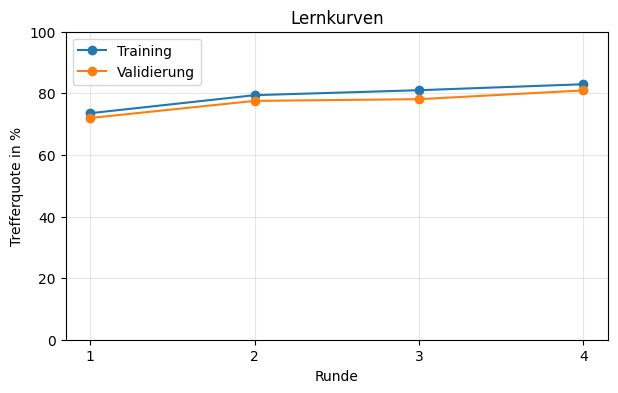

In [3]:
#@title E2 – Vier Runden trainieren und Lernkurven anzeigen { display-mode: "form" }
def get_accuracy(data_loader):
    model.eval()
    correct = 0
    total = 0
    with torch.no_grad():
        for images, labels in data_loader:
            predictions = model(images).argmax(dim=1)
            correct += int((predictions == labels).sum().item())
            total += len(labels)
    return 100 * correct / total


loss_fn = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=0.001)
rounds = [1, 2, 3, 4]
train_rates = []
validation_rates = []

for round_number in rounds:
    model.train()
    for images, labels in train_loader:
        scores = model(images)
        loss = loss_fn(scores, labels)
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

    train_rate = get_accuracy(train_check_loader)
    validation_rate = get_accuracy(validation_loader)
    train_rates.append(train_rate)
    validation_rates.append(validation_rate)
    print(
        f"Runde {round_number}: Training {train_rate:.1f} %, "
        f"Validierung {validation_rate:.1f} %"
    )

plt.figure(figsize=(7, 4))
plt.plot(rounds, train_rates, marker="o", label="Training")
plt.plot(rounds, validation_rates, marker="o", label="Validierung")
plt.xticks(rounds)
plt.ylim(0, 100)
plt.xlabel("Runde")
plt.ylabel("Trefferquote in %")
plt.title("Lernkurven")
plt.grid(alpha=0.3)
plt.legend()
plt.show()


## Experiment E3: Prüfung mit neuen Bildern

Führe die nächste Zelle aus. Erst **jetzt** prüft das Netz die **10'000 Testbilder**. Diese Bilder wurden zum Lernen und für die Lernkurven nicht benutzt.

Lies bei **E3** ab: Wie viele Testbilder erkennt das Netz richtig? Wie hoch ist die **Gesamttrefferquote** in Prozent? Eine gute Gesamtzahl verrät noch nicht, **welche Klassen** leicht oder schwierig sind.


In [4]:
#@title E3 – Testbilder prüfen { display-mode: "form" }
true_batches = []
prediction_batches = []
model.eval()
with torch.no_grad():
    for images, labels in test_loader:
        predictions = model(images).argmax(dim=1)
        true_batches.append(labels)
        prediction_batches.append(predictions)

true_labels = torch.cat(true_batches)
predicted_labels = torch.cat(prediction_batches)
test_correct = int((true_labels == predicted_labels).sum().item())
test_rate = 100 * test_correct / len(test_dataset)
print(f"Richtig: {test_correct:,} von {len(test_dataset):,} Testbildern".replace(",", "'"))
print(f"Gesamttrefferquote: {test_rate:.1f} %")


Richtig: 8'044 von 10'000 Testbildern
Gesamttrefferquote: 80.4 %


## Experiment E4: Wo verwechselt das Netz Klassen?

Führe die nächste Zelle aus. Sie zeigt eine **Konfusionsmatrix**. Lies sie so:

- **Zeile** = die **wahre** Klasse des Testbildes.
- **Spalte** = die Klasse, die das Netz **vorhergesagt** hat.
- Zahlen auf der **Diagonale** (links oben nach rechts unten) stehen für **richtige** Vorhersagen.
- Eine Zahl **neben** der Diagonale zählt eine Verwechslung.

Suche bei **E4** die grösste Verwechslung. Die Zelle nennt sie auch unter dem Diagramm. Trage die **wahre Klasse**, die **Vorhersage** und die **Anzahl** ein.


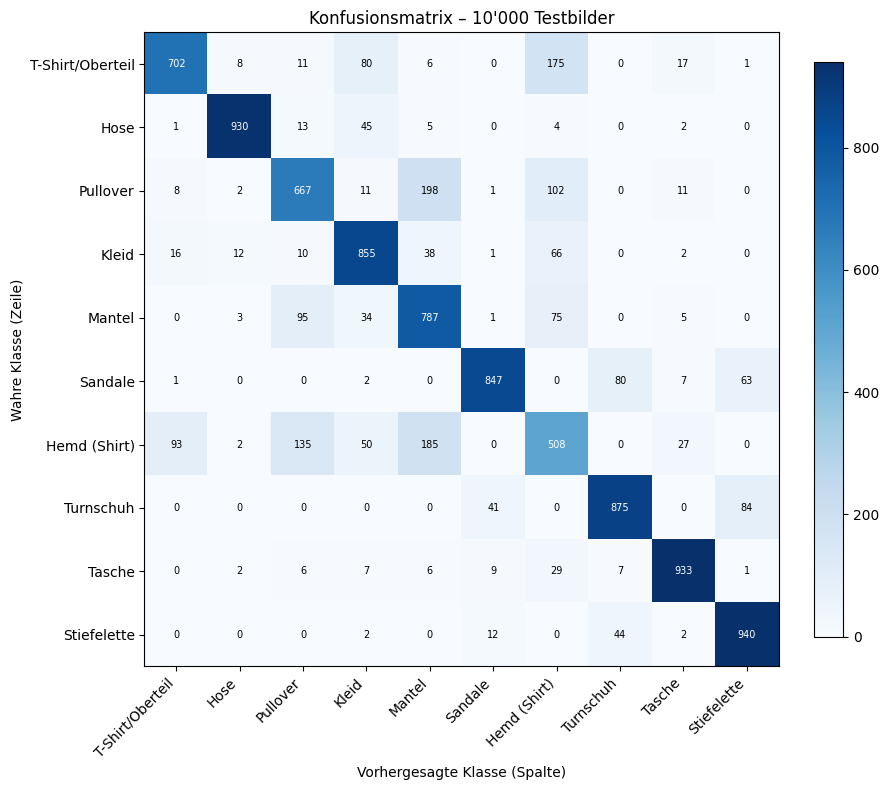

Grösste Verwechslung: wahr Pullover → vorhergesagt Mantel: 198 Bilder


In [5]:
#@title E4 – Konfusionsmatrix anzeigen { display-mode: "form" }
confusion = torch.bincount(
    true_labels * 10 + predicted_labels, minlength=100
).reshape(10, 10)

fig, ax = plt.subplots(figsize=(9, 8))
image_plot = ax.imshow(confusion.numpy(), cmap="Blues", vmin=0)
ax.set_xticks(range(10))
ax.set_xticklabels(class_names, rotation=45, ha="right")
ax.set_yticks(range(10))
ax.set_yticklabels(class_names)
ax.set_xlabel("Vorhergesagte Klasse (Spalte)")
ax.set_ylabel("Wahre Klasse (Zeile)")
ax.set_title("Konfusionsmatrix – 10'000 Testbilder")
for true_id in range(10):
    for predicted_id in range(10):
        value = int(confusion[true_id, predicted_id].item())
        ax.text(
            predicted_id, true_id, str(value), ha="center", va="center",
            fontsize=7, color="white" if value > 500 else "black",
        )
fig.colorbar(image_plot, ax=ax, fraction=0.04)
fig.tight_layout()
plt.show()

off_diagonal = confusion.clone()
off_diagonal.fill_diagonal_(-1)
largest_error = int(off_diagonal.max().item())
if largest_error > 0:
    # argmax wählt bei einem Gleichstand das erste Feld.
    flat_index = int(off_diagonal.flatten().argmax().item())
    most_confused_pair = (flat_index // 10, flat_index % 10)
    true_id, predicted_id = most_confused_pair
    print(
        f"Grösste Verwechslung: wahr {class_names[true_id]} "
        f"→ vorhergesagt {class_names[predicted_id]}: {largest_error} Bilder"
    )
else:
    most_confused_pair = None
    print("In dieser Ausführung gab es keine Verwechslung.")


## Experiment E5: Trefferquote je Klasse

Führe die nächste Zelle aus. Für jede wahre Klasse steht dort:

**richtig erkannte Bilder ÷ alle Testbilder dieser Klasse = Trefferquote**

Beispiel: 800 richtig von 1'000 bedeutet **80 %**. Die echten Zahlen siehst du erst nach dem Ausführen.

Schreibe bei **E5** die Klasse mit der **höchsten** und die mit der **tiefsten** Trefferquote auf. Lies die beiden Quoten ab. Erkläre kurz: **Was bedeutet eine tiefe Trefferquote für diese Klasse?**


In [6]:
#@title E5 – Trefferquote für jede Klasse { display-mode: "form" }
class_totals = confusion.sum(dim=1)
class_correct = confusion.diag()
class_rates = 100 * class_correct.float() / class_totals

for class_id, class_name in enumerate(class_names):
    correct = int(class_correct[class_id].item())
    total = int(class_totals[class_id].item())
    rate = float(class_rates[class_id].item())
    print(f"{class_id}: {class_name:<18} {correct:>4} von {total:>4} = {rate:>5.1f} %")

best_id = int(class_rates.argmax().item())
weakest_id = int(class_rates.argmin().item())
print(f"Höchste Trefferquote: {class_names[best_id]} ({class_rates[best_id]:.1f} %)")
print(f"Tiefste Trefferquote: {class_names[weakest_id]} ({class_rates[weakest_id]:.1f} %)")


0: T-Shirt/Oberteil    702 von 1000 =  70.2 %
1: Hose                930 von 1000 =  93.0 %
2: Pullover            667 von 1000 =  66.7 %
3: Kleid               855 von 1000 =  85.5 %
4: Mantel              787 von 1000 =  78.7 %
5: Sandale             847 von 1000 =  84.7 %
6: Hemd (Shirt)        508 von 1000 =  50.8 %
7: Turnschuh           875 von 1000 =  87.5 %
8: Tasche              933 von 1000 =  93.3 %
9: Stiefelette         940 von 1000 =  94.0 %
Höchste Trefferquote: Stiefelette (94.0 %)
Tiefste Trefferquote: Hemd (Shirt) (50.8 %)


## Experiment E6: Drei Fehlbilder ansehen

Führe die nächste Zelle aus. Sie zeigt **drei Testbilder**, bei denen das Netz falsch lag. **Fehlbild 1** gehört zur grössten Verwechslung aus E4. Unter jedem Bild steht die **wahre** und die **vorhergesagte** Klasse.

Wähle **ein** Fehlbild aus. Schreibe bei **E6** seine Bildnummer, die wahre Klasse und die Vorhersage auf. Schau genau hin: **Welches sichtbare Merkmal könnte das Netz verwirrt haben?** Schreibe eine kurze Vermutung. Erkläre auch kurz, **warum du die Ursache nicht sicher aus dem Bild ablesen kannst**.


Fehlbild 1: Testbild 48; wahr Pullover; vorhergesagt Mantel
Fehlbild 2: Testbild 8; wahr Sandale; vorhergesagt Turnschuh
Fehlbild 3: Testbild 12; wahr Turnschuh; vorhergesagt Sandale


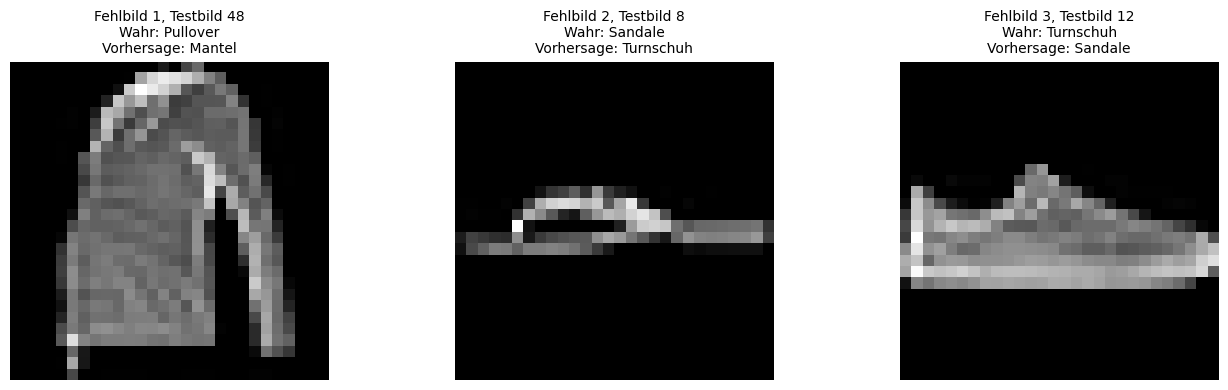

In [7]:
#@title E6 – Drei wirkliche Fehlbilder anzeigen { display-mode: "form" }
error_indices = torch.where(true_labels != predicted_labels)[0].tolist()
chosen_indices = []

# Das erste Bild kommt aus dem häufigsten Verwechslungspaar.
if most_confused_pair is not None:
    for index in error_indices:
        pair = (int(true_labels[index].item()), int(predicted_labels[index].item()))
        if pair == most_confused_pair:
            chosen_indices.append(index)
            break

# Nach Möglichkeit zwei weitere Arten von Fehlern zeigen.
shown_pairs = {
    (int(true_labels[index].item()), int(predicted_labels[index].item()))
    for index in chosen_indices
}
for index in error_indices:
    pair = (int(true_labels[index].item()), int(predicted_labels[index].item()))
    if index not in chosen_indices and pair not in shown_pairs:
        chosen_indices.append(index)
        shown_pairs.add(pair)
    if len(chosen_indices) == 3:
        break

for index in error_indices:
    if len(chosen_indices) == 3:
        break
    if index not in chosen_indices:
        chosen_indices.append(index)

if not chosen_indices:
    print("Keine Fehlbilder: Alle Testbilder wurden richtig erkannt.")
else:
    fig, axes = plt.subplots(1, len(chosen_indices), figsize=(4.5 * len(chosen_indices), 4))
    if len(chosen_indices) == 1:
        axes = [axes]
    for number, (axis, index) in enumerate(zip(axes, chosen_indices), start=1):
        image, true_id = test_dataset[index]
        predicted_id = int(predicted_labels[index].item())
        axis.imshow(image.squeeze(0), cmap="gray", vmin=0, vmax=1)
        axis.axis("off")
        axis.set_title(
            f"Fehlbild {number}, Testbild {index}\n"
            f"Wahr: {class_names[true_id]}\n"
            f"Vorhersage: {class_names[predicted_id]}",
            fontsize=10,
        )
        print(
            f"Fehlbild {number}: Testbild {index}; "
            f"wahr {class_names[true_id]}; "
            f"vorhergesagt {class_names[predicted_id]}"
        )
    fig.tight_layout()
    plt.show()


## Schluss

Beantworte im Leitprogramm die **Schlussfrage**: Was schaust du zusätzlich zur Gesamttrefferquote an? Nenne **zwei Dinge aus dieser Lektion**.

Fertig? Speichere dein **ausgefülltes Leitprogramm** und gib es wie besprochen ab. Das Colab musst du nicht abgeben.


Copyright 2026 [Markus Ineichen](mailto:markus.ineichen1@sluz.ch)

Code licence: [MIT License](https://mit-license.org/)

Text license: [Creative Commons Attribution-NonCommercial-ShareAlike 4.0 International](https://creativecommons.org/licenses/by-nc-sa/4.0/)